In [1]:
#Cell 1: Setup and load all test results
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

from src.config import CLASSES, FIG_DIR, MODELS_DIR, RESULTS_DIR

short = [c.replace("Potato___", "").replace("_", " ") for c in CLASSES]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Saved test results from notebooks 02-04 (no retraining needed)
RESULT_FILES = {
    "SmallCNN (scratch)": "small_cnn_test_results.json",
    "MobileNetV3 (frozen)": "mobilenet_v3_frozen_test_results.json",
    "ResNet18 (frozen)": "resnet18_frozen_test_results.json",
    "MobileNetV3 (fine-tuned)": "mnv3_finetune_all_ablation.json",
}

results = {}
for name, filename in RESULT_FILES.items():
    with open(RESULTS_DIR / filename) as f:
        data = json.load(f)
    preds, labels = data["test_preds"], data["test_labels"]
    results[name] = {"preds": preds, "labels": labels}
    print(f"{name:26s} acc {accuracy_score(labels, preds):.3f} | "
          f"macro F1 {f1_score(labels, preds, average='macro'):.3f}")

SmallCNN (scratch)         acc 0.985 | macro F1 0.977
MobileNetV3 (frozen)       acc 0.981 | macro F1 0.968
ResNet18 (frozen)          acc 0.969 | macro F1 0.935
MobileNetV3 (fine-tuned)   acc 0.997 | macro F1 0.991


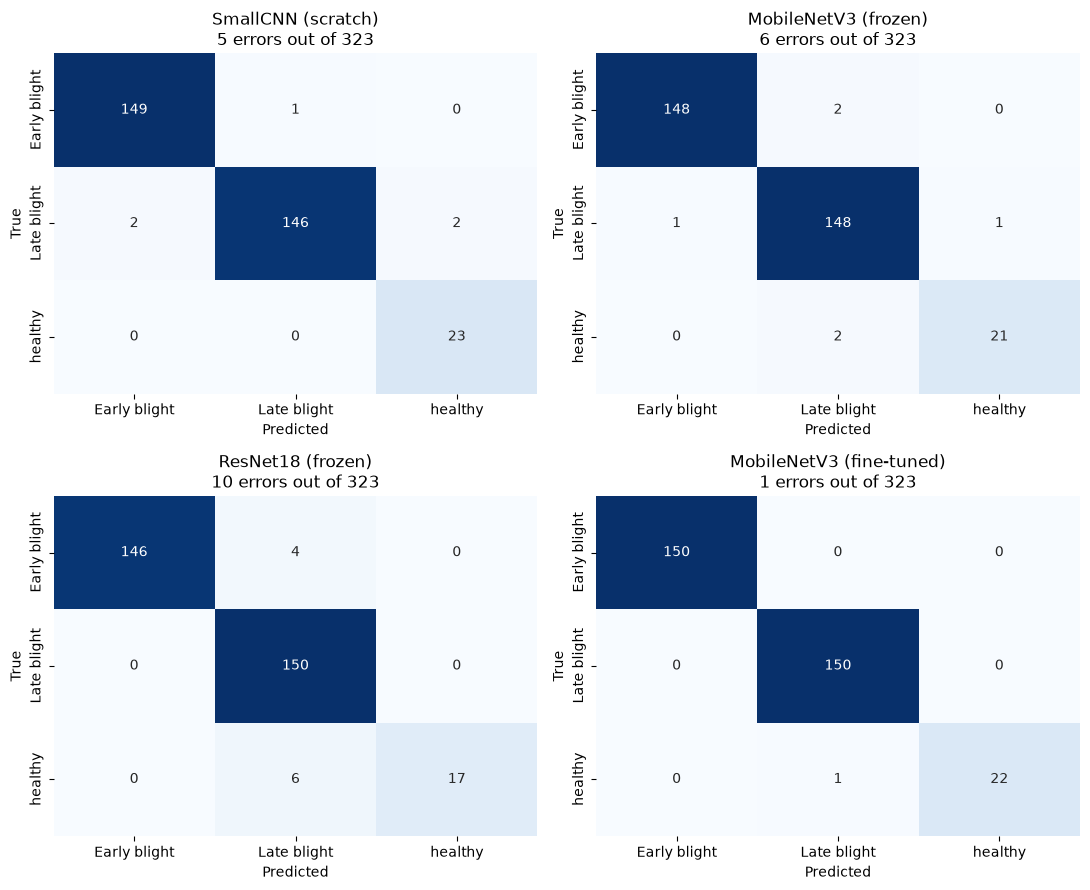

In [2]:
#Cell 2: Confusion matrices for all four models
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, r) in zip(axes.flat, results.items()):
    cm = confusion_matrix(r["labels"], r["preds"], labels=range(len(CLASSES)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=short, yticklabels=short, ax=ax)
    errors = cm.sum() - np.trace(cm)
    ax.set_title(f"{name}\n{errors} errors out of {cm.sum()}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=200)
plt.show()

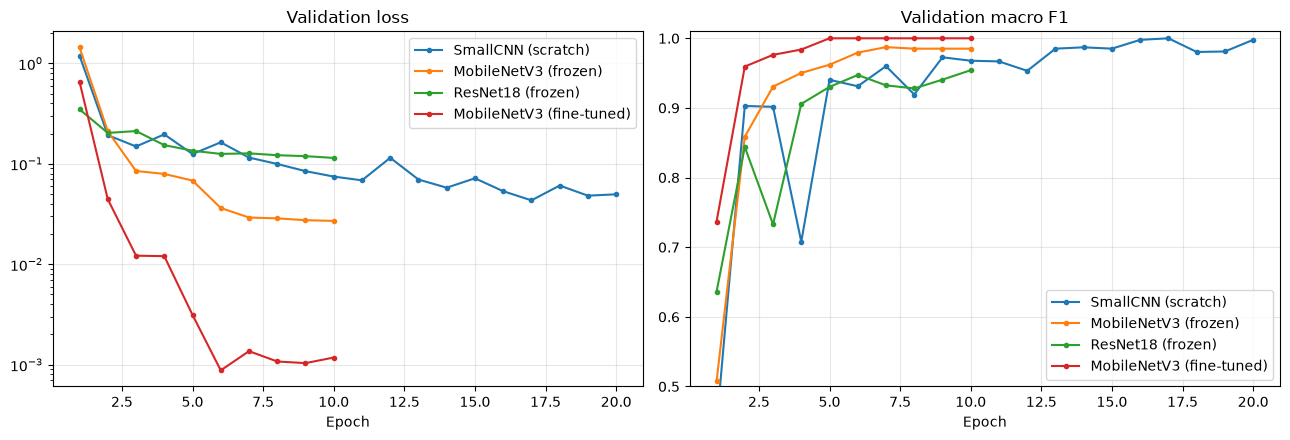

In [3]:
#Cell 3: Compare validation curves across models
HISTORY_FILES = {
    "SmallCNN (scratch)": RESULTS_DIR / "small_cnn_history.json",
    "MobileNetV3 (frozen)": RESULTS_DIR / "mobilenet_v3_frozen_history.json",
    "ResNet18 (frozen)": RESULTS_DIR / "resnet18_frozen_history.json",
    "MobileNetV3 (fine-tuned)": RESULTS_DIR / "mnv3_finetune_all_ablation.json",
}

histories = {}
for name, path in HISTORY_FILES.items():
    with open(path) as f:
        data = json.load(f)
    histories[name] = data["history"] if "history" in data else data

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in histories.items():
    epochs = range(1, len(h["val_f1"]) + 1)
    axes[0].plot(epochs, h["val_loss"], marker="o", markersize=3, label=name)
    axes[1].plot(epochs, h["val_f1"], marker="o", markersize=3, label=name)

axes[0].set_title("Validation loss")
axes[0].set_yscale("log")
axes[1].set_title("Validation macro F1")
axes[1].set_ylim(0.5, 1.01)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison_curves.png", dpi=200)
plt.show()

In [4]:
#Cell 4: Load the best model and set up Grad-CAM
import pandas as pd
import torch.nn.functional as F
from PIL import Image

from src.config import ROOT, SPLITS_DIR
from src.dataset import get_transforms
from src.models import build_mobilenet_v3

# Rebuild the architecture, then load the trained weights of the best model
best_model = build_mobilenet_v3(num_classes=len(CLASSES), freeze_backbone=False)
best_model.load_state_dict(torch.load(MODELS_DIR / "mnv3_finetune_all.pth", map_location=device))
best_model.to(device).eval()


class GradCAM:
    """Records the last conv layer's activations and gradients to build a heatmap."""

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)

    def _save_activation(self, module, inputs, output):
        self.activations = output
        output.register_hook(self._save_gradient)

    def _save_gradient(self, grad):
        self.gradients = grad

    def __call__(self, x, class_idx=None):
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(1).item()
        self.model.zero_grad()
        logits[0, class_idx].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)        # importance of each feature map
        cam = torch.relu((weights * self.activations).sum(dim=1))[0]    # weighted sum, keep positive
        cam = cam / (cam.max() + 1e-8)                                  # scale to 0-1
        confidence = torch.softmax(logits, dim=1)[0, class_idx].item()
        return cam.detach().cpu(), class_idx, confidence


gradcam = GradCAM(best_model, target_layer=best_model.features[-1])
print("Best model loaded, Grad-CAM ready")

Best model loaded, Grad-CAM ready


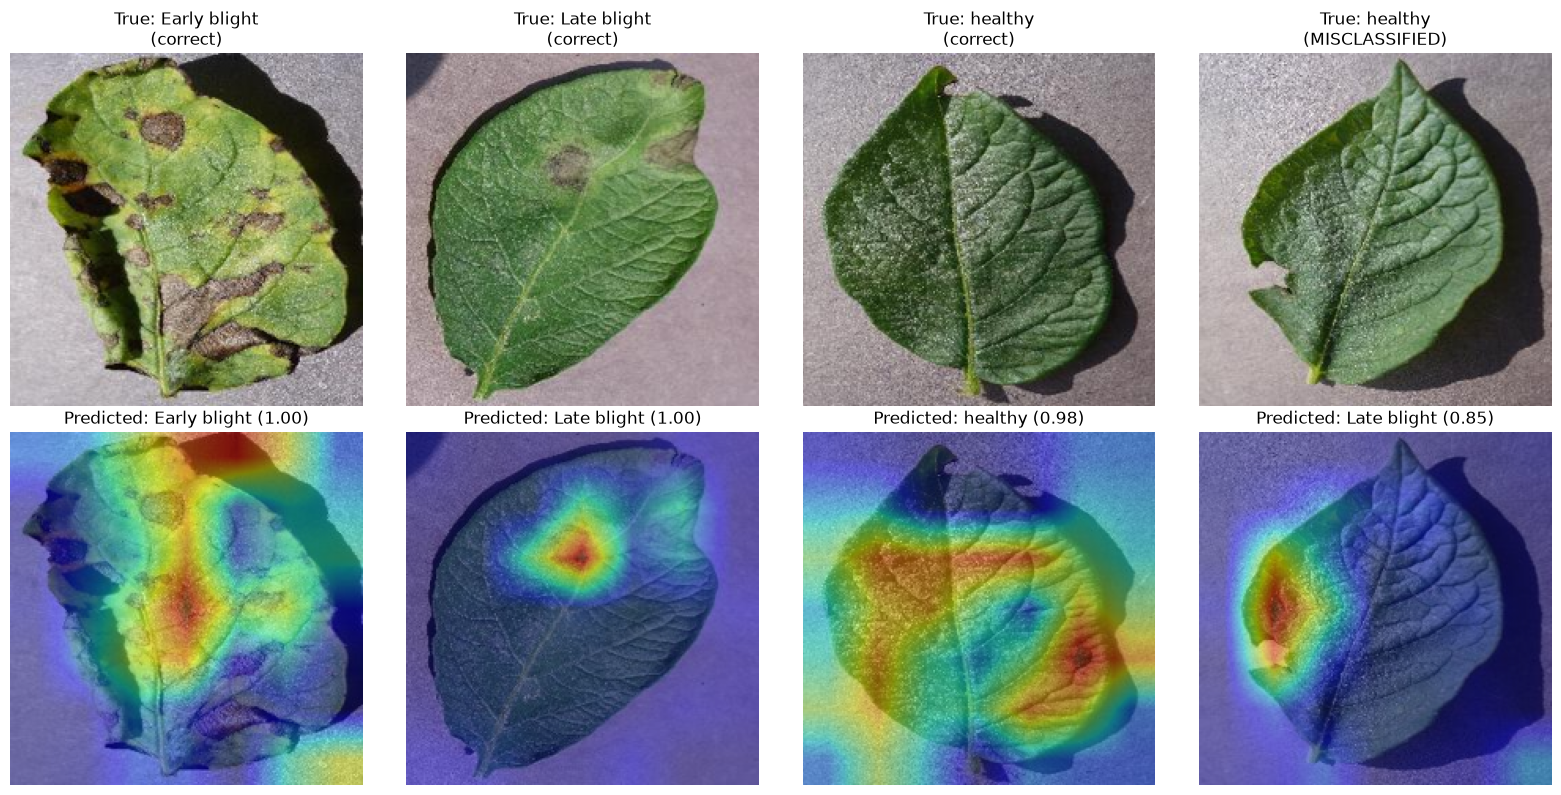

In [5]:
#Cell 5: Visualize what the model looks at
test_df = pd.read_csv(SPLITS_DIR / "test.csv")
best = results["MobileNetV3 (fine-tuned)"]
preds, labels = np.array(best["preds"]), np.array(best["labels"])

# One correctly classified example per class, plus every misclassified image
examples = [(np.where((labels == c) & (preds == c))[0][0], "correct") for c in range(len(CLASSES))]
examples += [(i, "MISCLASSIFIED") for i in np.where(preds != labels)[0]]

transform = get_transforms(augment=False)
fig, axes = plt.subplots(2, len(examples), figsize=(4 * len(examples), 8))

for col, (idx, tag) in enumerate(examples):
    row = test_df.iloc[idx]
    img = Image.open(ROOT / row["path"]).convert("RGB")
    x = transform(img).unsqueeze(0).to(device)

    cam, pred_idx, conf = gradcam(x)
    cam_up = F.interpolate(cam[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    shown = np.array(img.resize((224, 224))) / 255.0

    axes[0, col].imshow(shown)
    axes[0, col].set_title(f"True: {short[row['label']]}\n({tag})")
    axes[1, col].imshow(shown)
    axes[1, col].imshow(cam_up.numpy(), cmap="jet", alpha=0.45)
    axes[1, col].set_title(f"Predicted: {short[pred_idx]} ({conf:.2f})")
    for ax in axes[:, col]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "gradcam_best_model.png", dpi=200)
plt.show()